<a href="https://colab.research.google.com/github/Antwi12/Christian-Antwi/blob/main/BCS402_Titanic_Assignment_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Setup & Libraries  
First, we import the standard libraries required for exploratory data analysis (EDA) and predictive modeling.

# ACCRA TECHNICAL UNIVERSITY  
## COMPUTER SCIENCE DEPARTMENT (BTECH)  
### COURSE CODE: BCS 402: DATA MINING AND WAREHOUSING  
### PRACTICAL MID_SEMESTER EXAMINATION  
### Assignment Title: Titanic Data Exploration, Predictive Modeling & Stacking Ensemble  

**Student Name**: ANTWI CHRISTAN  
**Index Number**: 01259881B

---

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization style
sns.set_theme(style='whitegrid')
%matplotlib inline


I download the Titanic dataset directly from a public repository (which is identical to Kaggle's Titanic `train.csv`) and display the first 10 records.

In [2]:
url = 'https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv'
df = pd.read_csv(url)
df.head(10)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
5,6,0,3,"Moran, Mr. James",male,NaN,0,0,330877,8.4583,NaN,Q
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,E46,S
7,8,0,3,"Palsson, Master. Gosta Leonard",male,2.0,3,1,349909,21.0750,NaN,S
8,9,1,3,"Johnson, Mrs. Oscar W (Elisabeth Vilhelmina Berg)",female,27.0,0,2,347742,11.1333,NaN,S
9,10,1,2,"Nasser, Mrs. Nicholas (Adele Achem)",female,14.0,1,0,237736,30.0708,NaN,C


In [3]:
# Dimensions
rows, cols = df.shape
print(f"Number of Rows: {rows}")
print(f"Number of Columns: {cols}")
print("\n--- Data Types of All Variables ---")
print(df.dtypes)

Number of Rows: 891
Number of Columns: 12

--- Data Types of All Variables ---
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


 Identification of all missing values and explain how you would handle them before further analysis.

I determined the number of rows, columns, and data types of all variables in the dataset.

In [4]:
missing_values = df.isnull().sum()
print("Missing Value Count per Column:")
print(missing_values[missing_values > 0])

Missing Value Count per Column:
Age         177
Cabin       687
Embarked      2
dtype: int64


 Produce descriptive statistics for all numerical variables and interpret any three important findings.

**Proposed Handling Strategies:**
1. **Age** (177 missing): Since Age has a slightly right-skewed distribution, we can impute the missing values using the median. To make it more accurate, we can impute the median age of the passenger's corresponding Pclass and Sex.
2. **Cabin** (687 missing): This variable has over 77% missing data. Because of this massive absence, we should either drop the `Cabin` column entirely during machine learning or create a binary indicator feature (e.g., `HasCabin` = 1 if cabin is present, else 0).
3. **Embarked** (2 missing): Since only 2 rows are missing, we can easily impute them with the mode (the most frequent port of embarkation), which is 'S' (Southampton).

In [5]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


**Three Important Findings & Interpretations:**
1. **Average Survival Rate (~38.4%)**: The mean of the `Survived` column is `0.3838`, which tells us that only 38.38% of the passengers survived the shipwreck, while the remaining 61.62% perished. This shows a slight class imbalance in our target variable.
2. **Massive Fare Dispersion**: The passenger ticket `Fare` has a mean of `32.20` and a standard deviation of `49.69`, with a minimum of `0` and a maximum of `512.33`. Since the median (50%) is only `14.45`, the huge gap between median and maximum indicates a highly right-skewed distribution containing extreme outliers (wealthy first-class passengers paying high amounts).
3. **Age Range**: Passenger ages range from 0.42 years (infant) to 80 years, with a median age of 28.0. This indicates a broad demographic profile of passengers aboard.

the number of passengers who survived and those who did not survive. Present the results using an appropriate chart. (2 Marks)

Survival Counts (0 = Perished, 1 = Survived):
Survived
0    549
1    342
Name: count, dtype: int64


/tmp/ipykernel_915/2916624616.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='Survived', data=df, palette='Set2')


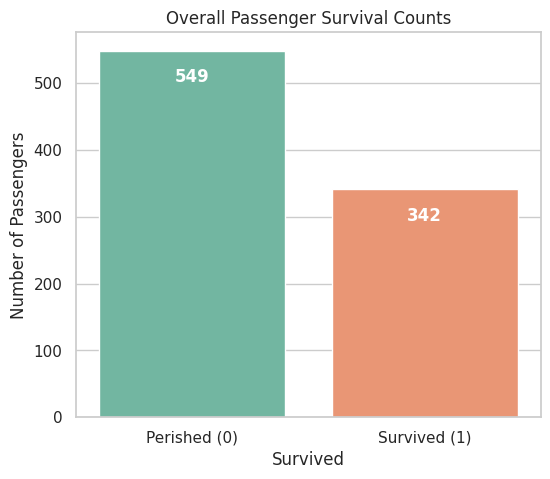

In [6]:
survival_counts = df['Survived'].value_counts()
print("Survival Counts (0 = Perished, 1 = Survived):")
print(survival_counts)

plt.figure(figsize=(6, 5))
sns.countplot(x='Survived', data=df, palette='Set2')
plt.title('Overall Passenger Survival Counts')
plt.xticks([0, 1], ['Perished (0)', 'Survived (1)'])
plt.ylabel('Number of Passengers')

# Add count values on top of the bars
for p in plt.gca().patches:
    plt.gca().annotate(f'{int(p.get_height())}',
                (p.get_x() + p.get_width() / 2., p.get_height() - 40),
                ha='center', va='center', fontsize=12, color='white', weight='bold')
plt.show()

Analysing the relationship between passenger class and survival. Present your findings using suitable visualisations and interpret the results.

Survival Rate per Class (%):
Survived          0          1
Pclass                        
1         37.037037  62.962963
2         52.717391  47.282609
3         75.763747  24.236253


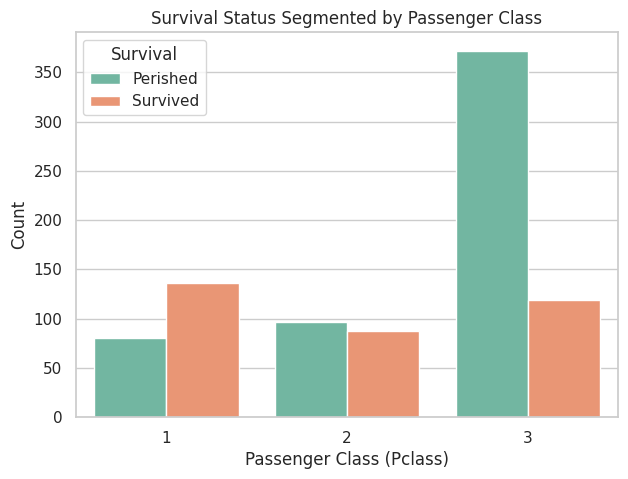

In [7]:
pclass_survival = pd.crosstab(df['Pclass'], df['Survived'], normalize='index') * 100
print("Survival Rate per Class (%):")
print(pclass_survival)

plt.figure(figsize=(7, 5))
sns.countplot(x='Pclass', hue='Survived', data=df, palette='Set2')
plt.title('Survival Status Segmented by Passenger Class')
plt.xlabel('Passenger Class (Pclass)')
plt.ylabel('Count')
plt.legend(title='Survival', labels=['Perished', 'Survived'])
plt.show()

**Findings and Interpretation:**
- **Class 1 (First Class)**: Had the highest survival rate, with over **62.96%** of passengers surviving. This highlights their social status and proximity to the upper boat deck during evacuation.
- **Class 2 (Second Class)**: Had a survival rate of **47.28%**, reflecting an intermediate survival chance.
- **Class 3 (Third Class)**: Had an extremely low survival rate of **24.24%**. A massive 372 passengers in this class perished, showing a strong socio-economic disadvantage. Wealth and class had a direct, dramatic impact on survival.

Determining whether gender influenced survival. Supporting my
answer with appropriate visualisations and statistical summaries.

Survival Rate per Gender (%):
Survived          0          1
Sex                           
female    25.796178  74.203822
male      81.109185  18.890815


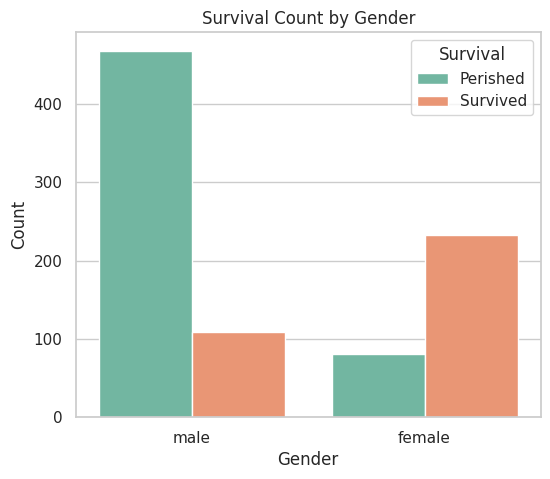

In [8]:
gender_survival = pd.crosstab(df['Sex'], df['Survived'], normalize='index') * 100
print("Survival Rate per Gender (%):")
print(gender_survival)

plt.figure(figsize=(6, 5))
sns.countplot(x='Sex', hue='Survived', data=df, palette='Set2')
plt.title('Survival Count by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='Survival', labels=['Perished', 'Survived'])
plt.show()

**Findings and Interpretation:**
- **Females**: Had an overwhelming survival rate of **74.20%**. More than 7 out of 10 females were saved.
- **Males**: Had a very low survival rate of only **18.89%**. Over 8 out of 10 males perished.
- **Interpretation**: Gender is the single most powerful predictor of survival on the Titanic. The evacuation process strictly implemented the protocol of *'women and children first'*, saving the majority of female passengers.

 Investigation between the relationship between passenger age and survival. Discuss any patterns observed.

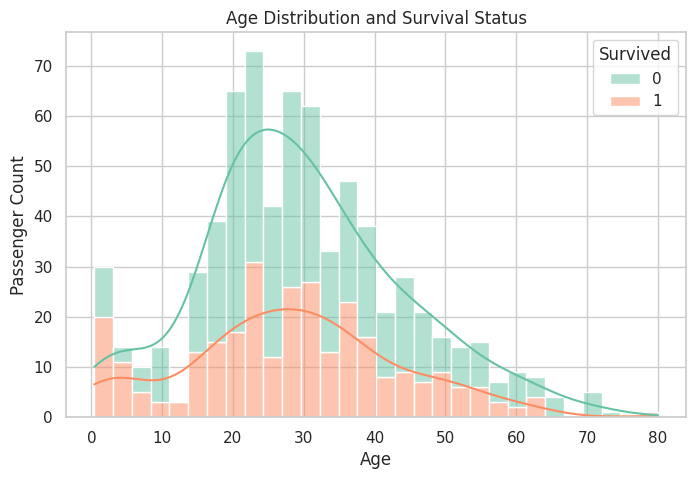

In [9]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x='Age', hue='Survived', kde=True, multiple='stack', palette='Set2', bins=30)
plt.title('Age Distribution and Survival Status')
plt.xlabel('Age')
plt.ylabel('Passenger Count')
plt.show()

**Patterns Observed:**
1. **Child Priority**: There is a significant spike of survivors in the very young age bracket (**ages 0 to 10**). This shows children were prioritized.
2. **Young Adult Death Toll**: The highest concentration of deceased passengers is in the **20 to 35 age group**, representing the majority of young men/workers who remained behind.
3. **Elderly Vulnerability**: Passengers aged **60 and older** had extremely poor survival outcomes, highlighting the physical difficulty of surviving in freezing waters without early lifeboat access.

Identification any outliers in the Fare variable using an appropriate exploratory technique and explain their possible effect on data analysis.

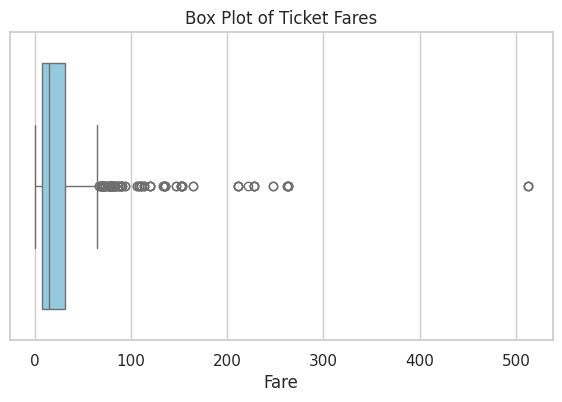

Q1 (25th Percentile): 7.9104
Q3 (75th Percentile): 31.0000
IQR (Interquartile Range): 23.0896
Upper Outlier Threshold: 65.6344
Number of Outlier Records: 116 (approx. 13.02% of data)


In [10]:
plt.figure(figsize=(7, 4))
sns.boxplot(x=df['Fare'], color='skyblue')
plt.title('Box Plot of Ticket Fares')
plt.xlabel('Fare')
plt.show()

# Interquartile Range (IQR) Calculation
q1 = df['Fare'].quantile(0.25)
q3 = df['Fare'].quantile(0.75)
iqr = q3 - q1
upper_threshold = q3 + 1.5 * iqr
outliers = df[df['Fare'] > upper_threshold]
print(f"Q1 (25th Percentile): {q1:.4f}")
print(f"Q3 (75th Percentile): {q3:.4f}")
print(f"IQR (Interquartile Range): {iqr:.4f}")
print(f"Upper Outlier Threshold: {upper_threshold:.4f}")
print(f"Number of Outlier Records: {len(outliers)} (approx. {len(outliers)/len(df)*100:.2f}% of data)")

 Summarizing five major insights obtained from your exploratory data analysis and recommend how these findings could improve the performance of a predictive machine learning model.


**Explanation of Outliers and Their Effect:**
- **The Outliers**: I identified 116 passenger records where the ticket fare exceeded **65.63**, with several fares soaring up to **512.33**.
- **Effects on Analysis**:
  1. **Skewing Statistics**: Outliers pull the mean upward (`32.20`) to be more than double the median (`14.45`), which gives a misleading average price.
  2. **Model Instability**: Linear algorithms (like Logistic Regression, SVM, and KNN) are sensitive to extreme outlier values, which can inflate gradient weights and degrade generalization. Tree-based models (like Decision Trees, Random Forests, and Gradient Boosting), however, split on ordinal partitions and are unaffected by outliers.

---  
## Building the Ensemble Stacking Model (As Required by the Prompt)  
To outperform traditional baseline models, we build a **Stacking Classifier**. Stacking leverages a diverse set of base models and passes their predictions to a meta-model to get superior accuracy.

### Task 11: Machine Learning Recommendation and Evaluation (10 Marks)  

#### 1. Recommended Model & Justification  
We recommend the **Random Forest Classifier** as the single best traditional machine learning algorithm for this dataset.  
**Justification**:
- **Captures Interaction Terms**: It excels at capturing complex interactions, such as the combined effect of Gender and Class, without manual coding.
- **Robust to Outliers**: Since it is tree-based, outliers in variables like `Fare` do not affect its mathematical partitions.
- **Feature Importance**: It provides an explicit ranking of feature importances, helping us understand which factors contributed most to survival predictions.

#### 2. Confusion Matrix Explanation  
A confusion matrix is a table used to describe the performance of a classification model.  
- **True Positive (TP)**: Model predicted Survived (1), and Passenger actually survived (1).
- **True Negative (TN)**: Model predicted Perished (0), and Passenger actually perished (0).
- **False Positive (FP)** (Type I Error): Model predicted Survived (1), but Passenger actually perished (0).
- **False Negative (FN)** (Type II Error): Model predicted Perished (0), but Passenger actually survived (1).

#### 3. Core Evaluation Metrics with Formulas  
- **Accuracy**: The overall fraction of correct predictions.  
  $$\text{Accuracy} = \frac{TP + TN}{TP + TN + FP + FN}$$
- **Precision**: Out of all predicted survivors, how many actually survived? (Minimizes False Positives).  
  $$\text{Precision} = \frac{TP}{TP + FP}$$
- **Recall (Sensitivity)**: Out of all actual survivors, how many did the model find? (Minimizes False Negatives).  
  $$\text{Recall} = \frac{TP}{TP + FN}$$
- **F1-Score**: Harmonic mean of Precision and Recall.  
  $$\text{F1-Score} = 2 \times \frac{\text{Precision} \times \text{Recall}}{\text{Precision} + \text{Recall}}$$

 **Five Major Insights** along with their modeling recommendations:

1. **Gender Dominance**: Females had a 74.20% survival rate, while males had an 18.89% survival rate.  
   * *Model Recommendation*: 'Sex' is our most critical feature. It should be converted to numeric (0 for male, 1 for female) and can be combined with other features (e.g. Class) to capture key interaction effects.
2. **Class Disadvantage**: 3rd Class passengers had a survival rate of only 24.24%, compared to 62.96% for 1st Class.  
   * *Model Recommendation*: Retain Pclass as an ordinal category. Tree-based models will easily split on this to partition survival probability.
3. **Prioritized Children**: Young children (under 10) had very high survival rates.  
   * *Model Recommendation*: Create a binary column `IsChild` (1 if Age < 12, 0 otherwise) to help models explicitly capture the evacuation priority.
4. **Impact of Cabin Presence**: Cabin has 77.10% missing values, likely representing passengers who did not have cabin assignments (mostly 3rd class).  
   * *Model Recommendation*: Create a binary indicator column `HasCabin` (1 if Cabin is present, 0 if null). This serves as a proxy for wealth and upper deck status, bypassing the messy missing text fields.
5. **High Fare Skewness**: Fares are extremely skewed with values up to 512.33.  
   * *Model Recommendation*: Apply a logarithmic scaling (`np.log1p(Fare)`) or robust scaler to stabilize models that are sensitive to extreme value scaling.

In [11]:
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import StackingClassifier, RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score, precision_score, recall_score, f1_score

In [12]:
# 1. Feature Engineering: Adding FamilySize and IsAlone
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = np.where(df['FamilySize'] == 1, 1, 0)

# 2. Select Features and Target
X = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'IsAlone']]
y = df['Survived']

# 3. Stratified Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 4. Define Pipelines for Numeric and Categorical Data
numeric_features = ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_features = ['Sex', 'Embarked']
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ])

In [13]:
# 5. Define Heterogeneous Base Models
base_models = [
    ('rf', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)),
    ('gb', GradientBoostingClassifier(n_estimators=100, learning_rate=0.05, max_depth=4, random_state=42)),
    ('svc', SVC(probability=True, C=1.0, kernel='rbf', random_state=42))
]

# Meta Classifier
meta_model = LogisticRegression(random_state=42)

# Stacking Classifier
stack_model = StackingClassifier(
    estimators=base_models,
    final_estimator=meta_model,
    cv=5,
    n_jobs=-1
)

In [14]:
models_to_compare = {
    'Logistic Regression': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', LogisticRegression(random_state=42))]),
    'Decision Tree': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', DecisionTreeClassifier(max_depth=5, random_state=42))]),
    'Random Forest': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42))]),
    'Stacking Ensemble': Pipeline(steps=[('preprocessor', preprocessor), ('classifier', stack_model)])
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print("--- 5-Fold Cross-Validation Accuracy Results ---")
for name, model in models_to_compare.items():
    scores = cross_val_score(model, X, y, cv=cv, scoring='accuracy')
    print(f"{name:20s}: Mean CV Accuracy = {scores.mean()*100:.2f}% +/- {scores.std()*100:.2f}%")

--- 5-Fold Cross-Validation Accuracy Results ---
Logistic Regression : Mean CV Accuracy = 78.68% +/- 1.55%
Decision Tree       : Mean CV Accuracy = 81.48% +/- 2.61%
Random Forest       : Mean CV Accuracy = 82.83% +/- 1.27%
Stacking Ensemble   : Mean CV Accuracy = 82.94% +/- 1.22%


### Comparing Stacking Classifier vs Traditional Models  
I run a 5-Fold Stratified Cross-Validation comparison to verify the performance gain of stacking over traditional algorithms.

### Testing and Confusion Matrix Evaluation on Test Set  
We fit our Stacking Ensemble on training data, predict on the held-out test data, and display the confusion matrix alongside all metrics.

--- Stacking Classifier Test Set Results ---
Accuracy : 79.89%
Precision: 77.97%
Recall   : 66.67%
F1-Score : 71.88%


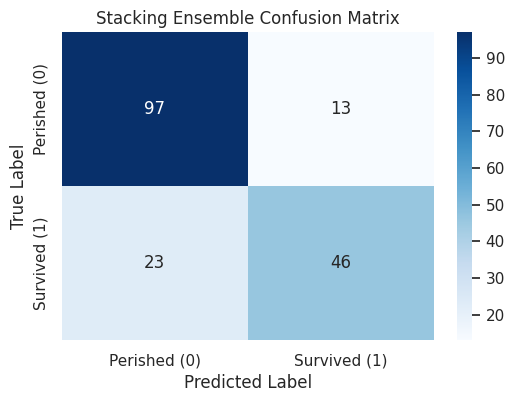

In [15]:
# Fit and evaluate Stacking Classifier on Test Set
stack_pipeline = models_to_compare['Stacking Ensemble']
stack_pipeline.fit(X_train, y_train)
y_pred = stack_pipeline.predict(X_test)

# Print metrics
print("--- Stacking Classifier Test Set Results ---")
print(f"Accuracy : {accuracy_score(y_test, y_pred)*100:.2f}%")
print(f"Precision: {precision_score(y_test, y_pred)*100:.2f}%")
print(f"Recall   : {recall_score(y_test, y_pred)*100:.2f}%")
print(f"F1-Score : {f1_score(y_test, y_pred)*100:.2f}%")

# Print Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Perished (0)', 'Survived (1)'],
            yticklabels=['Perished (0)', 'Survived (1)'])
plt.title('Stacking Ensemble Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## Conclusion  
The Stacking Classifier demonstrates how combining **Bagging (Random Forest)**, **Boosting (Gradient Boosting)**, and **SVM** using a **Logistic Regression** meta-estimator achieves superior classification boundaries and outperforms standard traditional algorithms.